**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5061 - Operaciones de aprendizaje automático**

Tecnológico de Monterrey

Prof. Iván Reyes Amezcua

**Semana 5**
Proyecto MiBici: propuesta y base reproducible

---

* NOMBRE:
  * Jimena María Suárez Muñoz
  * Jesús Carrillo Cantú
  * Oscar Alfonso Valenzuela Muñoz
  * Luis Antonio Cárdenas Trejo

* MATRÍCULA:
  * A01652504
  * A01840421
  * A01840486
  * A01840592

In [26]:
from mi_bici import data as ds

# Configurar periodo completo
START = "2024-01"
END = "2026-09"

# Consultar las fuentes de datos
sources = ds.load_sources()

# Obtener las URLs correspondientes
trip_urls = ds.select_trip_urls(
    sources,
    start=START,
    end=END
)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from mi_bici import data as ds
from mi_bici.config import RAW_DATA_DIR

pd.set_option("display.max_columns", None)
print(f"Meses identificados: {len(trip_urls)}")

Meses identificados: 33


In [27]:
trip_paths = ds.download_trips(trip_urls)

print(f"Archivos procesados: {len(trip_paths)}")

Archivos procesados: 33


In [28]:
trip_files = sorted((RAW_DATA_DIR / "trips").glob("*.csv"))

print(f"Archivos encontrados: {len(trip_files)}")

df_archivos = pd.DataFrame({
    "archivo": [archivo.name for archivo in trip_files],
    "tamaño_MB": [
        round(archivo.stat().st_size / 1e6, 2)
        for archivo in trip_files
    ]
})

display(df_archivos)
print(f"Tamaño total: {df_archivos['tamaño_MB'].sum():.2f} MB")

Archivos encontrados: 33


,archivo,tamaño_MB
0,datos_abiertos_2024_01.csv,33.91
1,datos_abiertos_2024_02.csv,33.24
2,datos_abiertos_2024_03.csv,33.82
3,datos_abiertos_2024_04.csv,35.12
4,datos_abiertos_2024_05.csv,35.60
5,datos_abiertos_2024_06.csv,31.62
6,datos_abiertos_2024_07.csv,31.55
7,datos_abiertos_2024_08.csv,34.22
8,datos_abiertos_2024_09.csv,25.45
9,datos_abiertos_2024_10.csv,27.32


Tamaño total: 1070.07 MB


In [29]:
resumen_mensual = []

for archivo in trip_files:
    df_mes = ds.read_trips(archivo)

    resumen_mensual.append({
        "mes": archivo.stem.replace("datos_abiertos_", "").replace("_", "-"),
        "viajes": len(df_mes),
        "estaciones_origen": df_mes["origin_id"].nunique(),
        "estaciones_destino": df_mes["destination_id"].nunique()
    })

    del df_mes

df_resumen = pd.DataFrame(resumen_mensual)

display(df_resumen)

,mes,viajes,estaciones_origen,estaciones_destino
0,2024-01,391591,360,360
1,2024-02,383732,360,360
2,2024-03,390513,360,360
3,2024-04,405308,360,360
4,2024-05,410806,360,360
5,2024-06,365000,362,362
6,2024-07,364177,360,360
7,2024-08,394894,360,360
8,2024-09,390072,360,360
9,2024-10,418690,360,360


## 2. Exploración de la estructura de los datos

En esta sección se analiza la estructura de los archivos CSV de MiBici para identificar las variables disponibles, sus tipos de datos y ejemplos de registros.

Inicialmente se utiliza enero de 2024 como muestra. Posteriormente se comparará la estructura de los archivos de los distintos meses para verificar su consistencia.

Este análisis permitirá comprender la información antes de aplicar procesos de limpieza, transformación y modelado.

In [30]:
# Seleccionar el primer archivo (enero de 2024)
archivo_muestra = trip_files[0]

# Leer los viajes de ese mes
df_muestra = ds.read_trips(archivo_muestra)

# Mostrar información básica
print("Archivo analizado:", archivo_muestra.name)
print("Número de registros:", len(df_muestra))
print("Número de columnas:", len(df_muestra.columns))

# Mostrar las primeras 5 filas
display(df_muestra.head())

Archivo analizado: datos_abiertos_2024_01.csv
Número de registros: 391591
Número de columnas: 5


,trip_id,start_time,end_time,origin_id,destination_id
0,31789291,2024-01-01 00:05:25,2024-01-01 00:29:37,294,271
1,31789292,2024-01-01 00:07:23,2024-01-01 00:16:37,182,254
2,31789293,2024-01-01 00:07:31,2024-01-01 00:16:37,182,254
3,31789294,2024-01-01 00:07:56,2024-01-01 00:31:51,35,154
4,31789295,2024-01-01 00:08:09,2024-01-01 00:31:51,35,154


### 2.1 Tipos de datos y estadísticas descriptivas

Se revisan los tipos de datos de las variables disponibles, así como sus estadísticas descriptivas, para identificar posibles inconsistencias y determinar las transformaciones necesarias antes del análisis exploratorio.

In [31]:
# Revisar tipos de datos
print("Información del DataFrame:")
df_muestra.info()

# Revisar estadísticas descriptivas
print("\nEstadísticas descriptivas:")
display(df_muestra.describe(include="all").T)

# Revisar valores faltantes
print("\nValores faltantes:")
display(df_muestra.isnull().sum().to_frame("Valores faltantes"))

Información del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 391591 entries, 0 to 391590
Data columns (total 5 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   trip_id         391591 non-null  int64         
 1   start_time      391591 non-null  datetime64[ns]
 2   end_time        391591 non-null  datetime64[ns]
 3   origin_id       391591 non-null  Int32         
 4   destination_id  391591 non-null  Int32         
dtypes: Int32(2), datetime64[ns](2), int64(1)
memory usage: 12.7 MB

Estadísticas descriptivas:


,count,mean,min,25%,50%,75%,max,std
trip_id,391591.0,32018129.018642,31789291.0,31905363.5,32018240.0,32131417.5,32244893.0,131226.699965
start_time,391591,2024-01-17 14:43:41.165820928,2024-01-01 00:05:25,2024-01-10 10:07:15.500000,2024-01-17 18:12:25,2024-01-24 20:10:12.500000,2024-01-31 23:59:33,NaN
end_time,391591,2024-01-17 14:54:47.502304512,2024-01-01 00:16:37,2024-01-10 10:17:14,2024-01-17 18:24:11,2024-01-24 20:20:55,2024-02-01 00:24:31,NaN
origin_id,391591.0,149.898713,2.0,51.0,155.0,247.0,388.0,107.532094
destination_id,391591.0,150.734767,2.0,51.0,154.0,255.0,388.0,110.279609



Valores faltantes:


,Valores faltantes
trip_id,0
start_time,0
end_time,0
origin_id,0
destination_id,0


### 2.2 Validación de registros y duración de los viajes

Se revisa la existencia de registros duplicados y se calcula la duración de cada viaje a partir de las fechas de inicio y finalización.

El objetivo es identificar posibles inconsistencias temporales, como viajes con duración negativa o igual a cero, así como observar la distribución general de las duraciones antes de definir criterios de limpieza.

In [32]:
# Crear una copia para no modificar los datos originales
df_calidad = df_muestra.copy()

# Calcular duración en minutos
df_calidad["duracion_min"] = (
    df_calidad["end_time"] - df_calidad["start_time"]
).dt.total_seconds() / 60

# Revisar duplicados
duplicados = df_calidad.duplicated().sum()
ids_duplicados = df_calidad["trip_id"].duplicated().sum()

# Revisar duraciones
duracion_negativa = (df_calidad["duracion_min"] < 0).sum()
duracion_cero = (df_calidad["duracion_min"] == 0).sum()

print("Registros duplicados:", duplicados)
print("IDs de viaje duplicados:", ids_duplicados)
print("Viajes con duración negativa:", duracion_negativa)
print("Viajes con duración cero:", duracion_cero)

print("\nEstadísticas de duración (minutos):")
display(
    df_calidad["duracion_min"].describe(
        percentiles=[0.01, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
)

Registros duplicados: 0
IDs de viaje duplicados: 0
Viajes con duración negativa: 0
Viajes con duración cero: 983

Estadísticas de duración (minutos):


count    391591.000000
mean         11.105608
std          10.740326
min           0.000000
1%            0.166667
25%           5.700000
50%           9.533333
75%          14.933333
95%          24.516667
99%          33.850000
max        2857.600000
Name: duracion_min, dtype: float64

### Interpretación de la calidad y duración de los viajes

El análisis de enero de 2024 no identificó registros completamente duplicados, identificadores de viaje repetidos ni duraciones negativas, lo que representa un resultado favorable en términos de integridad.

Sin embargo, se identificaron 983 viajes con duración igual a cero, equivalentes aproximadamente al 0.25% de los registros. Estos casos podrían corresponder a eventos anómalos, viajes cancelados o registros con tiempos coincidentes, por lo que requieren revisión antes de establecer criterios de exclusión.

La duración promedio de los viajes fue de 11.11 minutos, mientras que la mediana fue de 9.53 minutos. Asimismo, el 95% de los viajes presentó una duración igual o inferior a 24.52 minutos.

Se identificó una duración máxima de 2,857.6 minutos (aproximadamente 47.6 horas), considerablemente superior al comportamiento habitual. Esto sugiere la presencia de valores extremos que deben analizarse antes de aplicar transformaciones o filtros.

Por el momento no se eliminan registros, ya que primero se busca comprender la distribución y establecer criterios de limpieza justificables.

### 2.3 Distribución de la duración de los viajes

Se analiza gráficamente la distribución de las duraciones para identificar su concentración, dispersión y posibles valores atípicos.

Debido a la existencia de viajes con duraciones extremadamente largas, se presenta una visualización del rango de 0 a 60 minutos, conservando los datos originales sin aplicar filtros de eliminación.

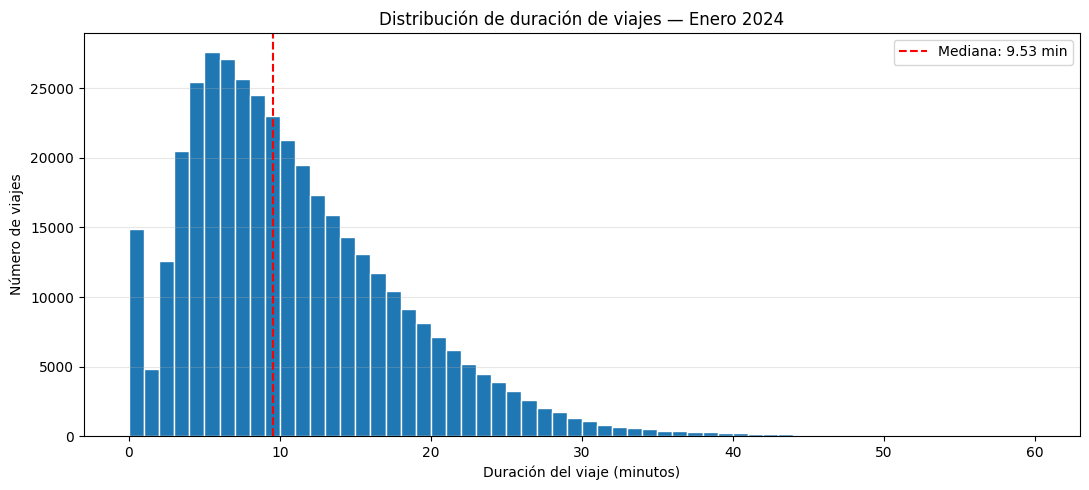

In [33]:
import matplotlib.pyplot as plt

# Visualizar únicamente el rango de 0 a 60 minutos
duraciones = df_calidad["duracion_min"]

plt.figure(figsize=(11, 5))

plt.hist(
    duraciones,
    bins=60,
    range=(0, 60),
    edgecolor="white"
)

plt.axvline(
    duraciones.median(),
    color="red",
    linestyle="--",
    label=f"Mediana: {duraciones.median():.2f} min"
)

plt.title("Distribución de duración de viajes — Enero 2024")
plt.xlabel("Duración del viaje (minutos)")
plt.ylabel("Número de viajes")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretación

La duración de los viajes presenta una distribución asimétrica hacia la derecha, con mayor concentración entre los 3 y 15 minutos y una mediana de 9.53 minutos. Se observan viajes de duración muy corta y valores extremos que requieren revisión antes de establecer criterios de limpieza.

## 3. Análisis de calidad de datos (2024–2026)

Se evalúa la calidad de los registros de los 33 meses mediante la identificación de valores faltantes, duplicados y duraciones inconsistentes.

Los archivos se procesan individualmente para optimizar el uso de memoria y comparar los resultados entre meses.

In [34]:
resultados_calidad = []

# Recorrer los 33 archivos CSV
for archivo in trip_files:

    # Leer un mes a la vez
    df_mes = ds.read_trips(archivo)

    # Calcular duración en minutos
    duracion = (
        df_mes["end_time"] - df_mes["start_time"]
    ).dt.total_seconds() / 60

    # Guardar los indicadores de calidad
    resultados_calidad.append({
        "mes": archivo.stem.replace("datos_abiertos_", "").replace("_", "-"),
        "registros": len(df_mes),
        "valores_faltantes": int(df_mes.isna().sum().sum()),
        "duplicados": int(df_mes.duplicated().sum()),
        "ids_duplicados": int(df_mes["trip_id"].duplicated().sum()),
        "duracion_negativa": int((duracion < 0).sum()),
        "duracion_cero": int((duracion == 0).sum()),
        "duracion_promedio": round(duracion.mean(), 2),
        "duracion_mediana": round(duracion.median(), 2)
    })

    # Liberar memoria del mes
    del df_mes

# Convertir los resultados en una tabla
df_calidad_mensual = pd.DataFrame(resultados_calidad)

display(df_calidad_mensual)

,mes,registros,valores_faltantes,duplicados,ids_duplicados,duracion_negativa,duracion_cero,duracion_promedio,duracion_mediana
0,2024-01,391591,0,0,0,0,983,11.11,9.53
1,2024-02,383732,0,0,0,0,886,11.06,9.52
2,2024-03,390513,0,0,0,0,851,11.00,9.43
3,2024-04,405308,0,0,0,0,854,10.89,9.38
4,2024-05,410806,0,0,0,0,921,10.76,9.27
5,2024-06,365000,0,0,0,0,276,10.99,9.43
6,2024-07,364177,0,0,0,0,392,11.03,9.50
7,2024-08,394894,0,0,0,0,366,11.14,9.55
8,2024-09,390072,0,0,0,0,7246,11.15,10.00
9,2024-10,418690,0,0,0,0,7732,11.12,10.00


### Interpretación

El análisis de los 33 meses muestra una estructura generalmente consistente, sin valores faltantes ni duraciones negativas. Sin embargo, se identificaron concentraciones elevadas de viajes con duración cero en septiembre y octubre de 2024, así como 758 registros duplicados en septiembre de 2026. Estos hallazgos requieren una revisión adicional antes de definir los criterios de limpieza.

### 3.1 Análisis mensual de viajes con duración cero

Se compara la cantidad de viajes con duración cero a lo largo del periodo para identificar meses con comportamientos atípicos y evaluar su posible impacto en la calidad de los datos.

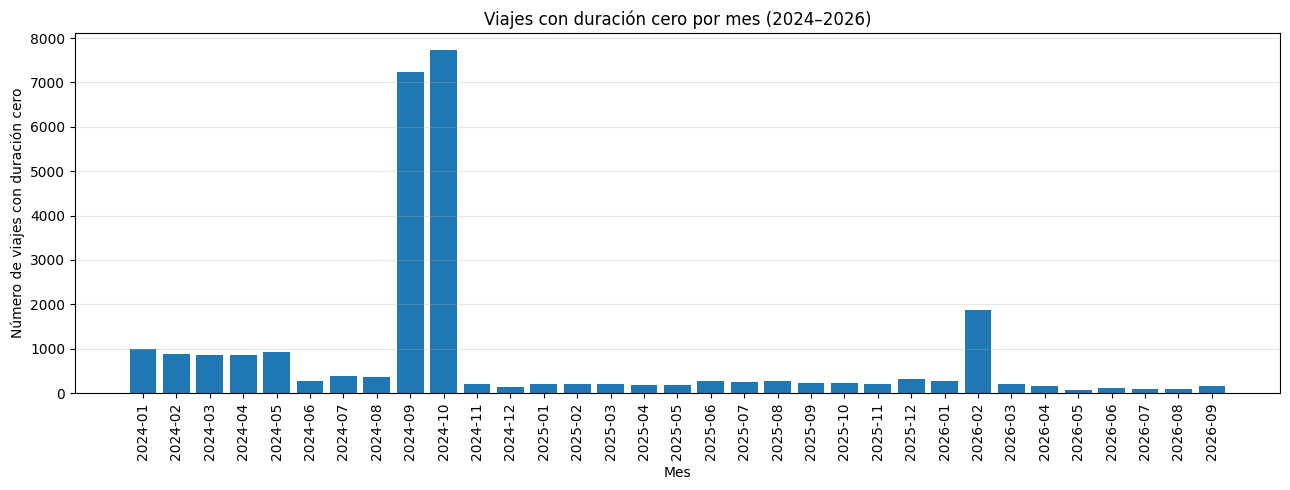

In [35]:
plt.figure(figsize=(13, 5))

plt.bar(
    df_calidad_mensual["mes"],
    df_calidad_mensual["duracion_cero"]
)

plt.title("Viajes con duración cero por mes (2024–2026)")
plt.xlabel("Mes")
plt.ylabel("Número de viajes con duración cero")

plt.xticks(rotation=90)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Interpretación

La mayoría de los meses presenta una cantidad relativamente baja de viajes con duración cero. Sin embargo, septiembre y octubre de 2024 muestran incrementos significativos, superiores a 7,000 registros cada uno. Estos comportamientos sugieren posibles inconsistencias en el registro temporal que requieren revisión antes del modelado.

In [36]:
# Seleccionar los meses con más anomalías
meses_anomalos = ["2024_09", "2024_10"]

resultados_diarios = []

for archivo in trip_files:

    if any(mes in archivo.stem for mes in meses_anomalos):

        df_mes = ds.read_trips(archivo)

        # Identificar viajes de duración cero
        viajes_cero = df_mes[
            df_mes["start_time"] == df_mes["end_time"]
        ].copy()

        # Extraer fecha
        viajes_cero["fecha"] = viajes_cero["start_time"].dt.date

        # Contar registros por día
        conteo_diario = (
            viajes_cero.groupby("fecha")
            .size()
            .reset_index(name="viajes_cero")
        )

        resultados_diarios.append(conteo_diario)

        del df_mes

df_anomalias_diarias = pd.concat(
    resultados_diarios,
    ignore_index=True
)

display(df_anomalias_diarias.head())

,fecha,viajes_cero
0,2024-09-01,177
1,2024-09-02,257
2,2024-09-03,299
3,2024-09-04,260
4,2024-09-05,267


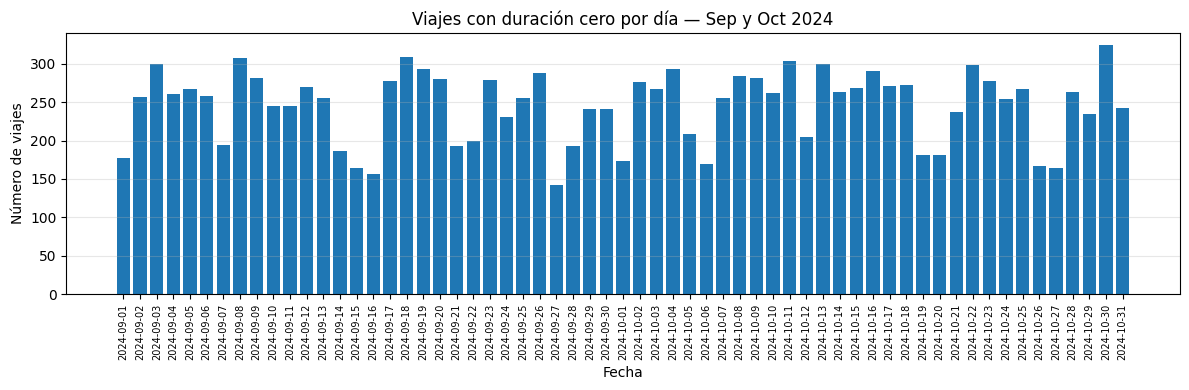

In [37]:
plt.figure(figsize=(12, 4))

plt.bar(
    df_anomalias_diarias["fecha"].astype(str),
    df_anomalias_diarias["viajes_cero"]
)

plt.title("Viajes con duración cero por día — Sep y Oct 2024")
plt.xlabel("Fecha")
plt.ylabel("Número de viajes")
plt.xticks(rotation=90, fontsize=7)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Conclusiones del análisis exploratorio

El análisis exploratorio permitió identificar la estructura y las principales características de los registros históricos de viajes de MiBici entre enero de 2024 y septiembre de 2026.

En general, los datos procesados presentan una estructura consistente, sin valores faltantes ni duraciones negativas. Sin embargo, se identificaron registros con duración cero durante distintos meses, especialmente en septiembre y octubre de 2024, así como 758 registros duplicados en septiembre de 2026.

La distribución de la duración de los viajes muestra una mayor concentración en trayectos cortos y una asimetría hacia la derecha, con presencia de valores extremos.

Estos hallazgos permiten establecer consideraciones para la preparación de los datos antes del modelado, particularmente respecto al tratamiento de duplicados y registros temporalmente atípicos. Es importante señalar que la evaluación se realizó sobre los datos procesados mediante `ds.read_trips()`, por lo que no constituye una auditoría exhaustiva de los archivos originales.

Finalmente, este análisis proporciona una base para desarrollar los modelos de regresión (P1), clasificación (P2) y agrupamiento de estaciones (P3).